# Etapa 4 · Treino com rótulos humanos

| | |
|---|---|
| **Pergunta** | Até onde a arquitetura chega quando aprende com rótulos humanos? |
| **Entrada** | `entregas/01_dados/` (dados), `entregas/02_avaliacao/` (régua e linha de base) e a rede da Etapa 3. |
| **Entrega** | O laço de treino (`src/especialista/treino.py`) e `entregas/04_treino/`: três modelos treinados (um por semente), resultados em `dev` e teste, comparações, figuras e resumo. |
| **Pronto quando** | (1) a configuração final tem 3 sementes treinadas; (2) cada comparação foi decidida em `dev` pela regra escrita antes do resultado; (3) o modelo supera a linha de base em exact match de forma distinguível; (4) o teste foi aberto uma vez, com intervalo de confiança; (5) os modelos relidos do disco reproduzem o resultado. |

**Por que esta etapa.** O modelo treinado aqui é o **teto** do projeto: o melhor que esta arquitetura faz com os rótulos certos. Nas etapas seguintes, os alunos vão aprender com rótulos de uma LLM, e a distância até este teto é o custo de trocar o professor humano pela LLM.

**Artigos-âncora**

- Receita de treino e comparações: Bunk et al., *DIET* ([arXiv 2004.09936](https://arxiv.org/abs/2004.09936)), seções 3, 4.2 e 4.4.
- Lote crescente: Smith et al., *Don't Decay the Learning Rate, Increase the Batch Size* ([arXiv 1711.00489](https://arxiv.org/abs/1711.00489)).
- Várias sementes: Reimers & Gurevych, *Reporting Score Distributions Makes a Difference* ([arXiv 1707.09861](https://arxiv.org/abs/1707.09861)).

**Roteiro**

1. A receita de treino
2. Como os experimentos rodam
3. O treino padrão
4. As comparações, decididas em `dev`
5. A configuração final
6. Resultado no teste
7. Onde o modelo ainda erra
8. Eficiência
9. Entrega
10. Resposta

In [1]:
import json
import shutil
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display

from especialista import visual
from especialista.avaliacao import eficiencia, qualidade, resultados
from especialista.avaliacao.previsao import carregar_previsoes, ouro, salvar_previsoes
from especialista.caminhos import ENTREGAS, RAIZ, entrega
from especialista.dados import massive
from especialista.experimentos import etapa4
from especialista.modelos.diet import Config, SistemaDiet
from especialista.treino import Receita, indices_da_epoca

visual.aplicar_estilo()
pd.set_option("display.max_colwidth", 140)
torch.set_num_threads(1)

PASTA = entrega("04_treino")
SEMENTES = etapa4.SEMENTES

particoes, rotulos = massive.carregar_entrega()
treino, dev, teste = (particoes[p] for p in ("train", "dev", "test"))
ouro_dev, ouro_teste = ouro(dev), ouro(teste)

# a linha de base da Etapa 2, para comparar de forma pareada
_, base_dev = carregar_previsoes(ENTREGAS / "02_avaliacao" / "previsoes" / "linha_de_base_dev.parquet")
_, base_teste = carregar_previsoes(ENTREGAS / "02_avaliacao" / "previsoes" / "linha_de_base_test.parquet")
base_csv = resultados.carregar(ENTREGAS / "02_avaliacao")
base_linha = base_csv[(base_csv["particao"] == "test") & base_csv["sistema"].str.startswith("Linha de base")].iloc[0]


def n(x):
    return f"{int(x):,}".replace(",", ".")


def num(x, casas=1):
    return f"{x:.{casas}f}".replace(".", ",")


def pts(x, casas=1):
    return num(100 * x, casas)


def dif(x):
    """Diferença entre duas frações, em pontos percentuais e com sinal: 0.0246 -> +2,5."""
    return f"{100 * x:+.1f}".replace(".", ",").replace("-", "−")


def sinal(x):
    """Número já em pontos, com sinal: -2.34 -> −2,3."""
    return f"{x:+.1f}".replace(".", ",").replace("-", "−")


print(f"PyTorch {torch.__version__} · GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'não'}")

PyTorch 2.15.0+cu132 · GPU: NVIDIA GeForce RTX 3080


## 1. A receita de treino

O ponto de partida é a receita do artigo do DIET. O que o artigo não detalha é decidido aqui e declarado.

In [2]:
receita = Receita()
ordem = indices_da_epoca(treino["intent"], receita.minimo_por_intencao, np.random.default_rng(0))
contagem = treino["intent"].value_counts()
repetidas = contagem[contagem < receita.minimo_por_intencao]

pd.DataFrame([
    ("Otimizador", "Adam", "Artigo"),
    ("Taxa de aprendizado", num(receita.taxa, 3), "Artigo"),
    ("Tamanho do lote", f"cresce de {receita.lote_inicial} para {receita.lote_final}, em linha reta", "Artigo (Smith et al.)"),
    ("Perda", "intenção + entidades + máscara, soma simples", "Artigo"),
    ("Lotes balanceados", f"cada intenção aparece pelo menos {receita.minimo_por_intencao} vezes por época", "Artigo cita, sem detalhar; a regra é deste projeto"),
    ("Épocas", f"até {receita.epocas}, com avaliação em dev a cada {receita.avaliar_a_cada}", "Artigo usa 200 fixas; aqui fica o melhor ponto em dev"),
    ("Critério do melhor ponto", "exact match em dev", "Regra da Etapa 2: decide-se em dev"),
    ("Lotes por comprimento parecido", "sim", "Engenharia: só muda a velocidade do treino"),
    ("Sementes", str(len(SEMENTES)), "Reimers & Gurevych"),
], columns=["item", "valor", "origem"]).set_index("item")

,valor,origem
item,,
Otimizador,Adam,Artigo
Taxa de aprendizado,"0,001",Artigo
Tamanho do lote,"cresce de 64 para 128, em linha reta",Artigo (Smith et al.)
Perda,"intenção + entidades + máscara, soma simples",Artigo
Lotes balanceados,cada intenção aparece pelo menos 100 vezes por época,"Artigo cita, sem detalhar; a regra é deste projeto"
Épocas,"até 80, com avaliação em dev a cada 5",Artigo usa 200 fixas; aqui fica o melhor ponto em dev
Critério do melhor ponto,exact match em dev,Regra da Etapa 2: decide-se em dev
Lotes por comprimento parecido,sim,Engenharia: só muda a velocidade do treino
Sementes,3,Reimers & Gurevych


In [3]:
display(Markdown(f"""
**O balanceamento, em números.** O treino tem {n(len(treino))} enunciados. {len(repetidas)} das 60 intenções têm menos de {receita.minimo_por_intencao} exemplos; elas são repetidas até {receita.minimo_por_intencao}. Cada época passa a ter {n(len(ordem))} exemplos ({pts(len(ordem) / len(treino) - 1)}% a mais). A menor intenção (`{contagem.idxmin()}`, {contagem.min()} exemplos) é vista {receita.minimo_por_intencao // contagem.min()} vezes por época.

**Por que o lote cresce.** Smith et al. mostram que aumentar o lote ao longo do treino tem efeito parecido com reduzir a taxa de aprendizado: passos ruidosos no começo, que exploram, e passos estáveis no fim, que assentam.

**Por que parar pelo `dev`.** A rede tem capacidade para decorar o treino (a Etapa 3 mostrou isso com 64 exemplos). O melhor modelo não é o da última época, é o que melhor generaliza, e isso se mede fora do treino.
"""))


**O balanceamento, em números.** O treino tem 11.514 enunciados. 18 das 60 intenções têm menos de 100 exemplos; elas são repetidas até 100. Cada época passa a ter 12.379 exemplos (7,5% a mais). A menor intenção (`cooking_query`, 4 exemplos) é vista 25 vezes por época.

**Por que o lote cresce.** Smith et al. mostram que aumentar o lote ao longo do treino tem efeito parecido com reduzir a taxa de aprendizado: passos ruidosos no começo, que exploram, e passos estáveis no fim, que assentam.

**Por que parar pelo `dev`.** A rede tem capacidade para decorar o treino (a Etapa 3 mostrou isso com 64 exemplos). O melhor modelo não é o da última época, é o que melhor generaliza, e isso se mede fora do treino.


## 2. Como os experimentos rodam

Cada execução treina um modelo do zero e leva alguns minutos de GPU. Para o notebook poder ser reexecutado sem treinar tudo de novo, cada execução grava o que produziu em `data/execucoes/04_treino/` e só roda outra vez se a pasta for apagada.

Uma **variante** muda uma única coisa em relação ao padrão. Cada variante roda com **3 sementes**: a mesma rede treinada duas vezes dá resultados um pouco diferentes, e comparar uma execução contra outra pode premiar a sorte (Reimers & Gurevych). O resultado de uma variante é a média das suas 3 execuções.

In [4]:
for variante in etapa4.VARIANTES:
    for semente in SEMENTES:
        etapa4.executar(variante, semente)   # treina se ainda não existe; senão só confere

execucoes = {v: [etapa4.carregar(v, s) for s in SEMENTES] for v in etapa4.VARIANTES}
grupo_dev = {v: [e["previsoes_dev"] for e in es] for v, es in execucoes.items()}

pd.DataFrame([
    {
        "variante": definicao["nome"],
        "o que muda": ", ".join(f"{k} = {valor}" for k, valor in {**definicao["config"], **definicao["receita"]}.items()) or "nada",
        "melhor época (por semente)": ", ".join(str(e["meta"]["melhor_epoca"]) for e in execucoes[v]),
        "minutos de treino (média)": num(np.mean([e["meta"]["segundos_de_treino"] for e in execucoes[v]]) / 60),
    }
    for v, definicao in etapa4.VARIANTES.items()
]).set_index("variante")

,o que muda,melhor época (por semente),minutos de treino (média)
variante,,,
Padrão (receita do artigo),nada,"80, 45, 65","10,1"
Sem a perda de máscara,peso_mascara = 0.0,"20, 15, 10","8,5"
Só intenção (sem a tarefa de entidades),"peso_entidades = 0.0, criterio = intent_acc","80, 30, 65","8,1"
Só entidades (sem a tarefa de intenção),"peso_intencao = 0.0, criterio = slot_f1","80, 80, 20","10,0"
Sem CRF (cada palavra escolhe a sua tag),usar_crf = False,"45, 45, 20","8,5"
Sem balancear as intenções nos lotes,minimo_por_intencao = 0,"70, 75, 20","9,7"
"Dropout de 0,4 (o padrão é 0,2)","dropout = 0.4, dropout_features = 0.4","80, 75, 70","10,1"


Os tempos de treino são de execuções que dividiram a mesma GPU, várias ao mesmo tempo. Sozinha, uma execução leva menos.

## 3. O treino padrão

Antes de comparar qualquer coisa, o treino da receita do artigo, nas 3 sementes.

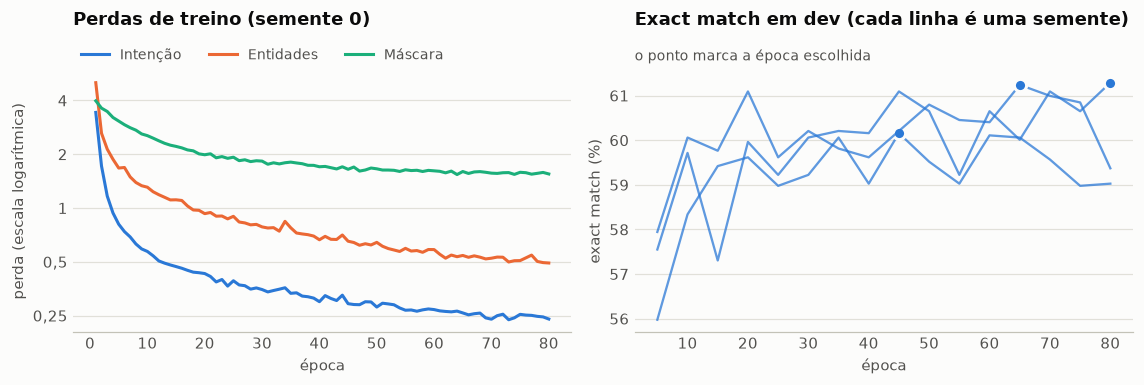

In [5]:
padrao = execucoes["padrao"]

fig, eixos = plt.subplots(1, 2, figsize=(10.5, 3.6))

# esquerda: perdas de treino (semente 0)
ax = eixos[0]
h = padrao[0]["historico"]
series = {"perda_intencao": ("Intenção", visual.AZUL), "perda_entidades": ("Entidades", visual.LARANJA), "perda_mascara": ("Máscara", "#1baf7a")}
for coluna, (nome, cor) in series.items():
    ax.plot(h["epoca"], h[coluna], color=cor, linewidth=2, label=nome)
ax.set_yscale("log")
ax.set_yticks([0.25, 0.5, 1, 2, 4], ["0,25", "0,5", "1", "2", "4"])
ax.minorticks_off()
ax.set_title("Perdas de treino (semente 0)", pad=30)
ax.set_xlabel("época")
ax.set_ylabel("perda (escala logarítmica)")
ax.yaxis.grid(True)
ax.spines["left"].set_visible(False)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncols=3, frameon=False, fontsize=9,
          labelcolor=visual.TINTA_SECUNDARIA, borderaxespad=0.2)

# direita: exact match em dev, uma linha por semente
ax = eixos[1]
for e in padrao:
    medido = e["historico"].dropna(subset=["dev_exact_match"])
    ax.plot(medido["epoca"], 100 * medido["dev_exact_match"], color=visual.AZUL, linewidth=1.5, alpha=0.75)
    melhor = medido[medido["melhor"]]
    ax.plot(melhor["epoca"], 100 * melhor["dev_exact_match"], "o", color=visual.AZUL, markersize=8,
            markeredgecolor=visual.SUPERFICIE, markeredgewidth=2)
ax.set_title("Exact match em dev (cada linha é uma semente)", pad=30)
ax.text(0, 1.04, "o ponto marca a época escolhida", transform=ax.transAxes, fontsize=9, color=visual.TINTA_SECUNDARIA)
ax.set_xlabel("época")
ax.set_ylabel("exact match (%)")
ax.yaxis.grid(True)
ax.yaxis.set_major_formatter(visual.VIRGULA)
ax.spines["left"].set_visible(False)
fig.tight_layout()
visual.salvar(fig, PASTA, "treino_padrao")
plt.show()

In [6]:
por_semente = pd.DataFrame([qualidade.avaliar(ouro_dev, prev) for prev in grupo_dev["padrao"]], index=[f"semente {s}" for s in SEMENTES])
resumo_padrao = por_semente[list(qualidade.METRICAS)].rename(columns=qualidade.NOMES)
tabela = resumo_padrao.map(pts)
tabela.loc["média"] = resumo_padrao.mean().map(pts)
tabela.loc["desvio entre sementes"] = resumo_padrao.std(ddof=1).map(pts)
display(tabela)

medido = padrao[0]["historico"].dropna(subset=["dev_exact_match"])
meio, fim = medido.iloc[len(medido) // 2 - 1], medido.iloc[-1]
soma = lambda linha: linha["perda_intencao"] + linha["perda_entidades"]
display(Markdown(f"""
**Leitura.**

- Na semente 0, da época {int(meio['epoca'])} à época {int(fim['epoca'])}, a perda de treino (intenção + entidades) cai de {num(soma(meio), 2)} para {num(soma(fim), 2)}, e o exact match em `dev` vai de {pts(meio['dev_exact_match'])} para {pts(fim['dev_exact_match'])}. A perda de treino não diz quando a rede parou de generalizar; por isso o ponto de parada é escolhido em `dev`.
- A variação entre sementes é de {pts(por_semente['exact_match'].std(ddof=1))} de desvio-padrão em exact match. Uma diferença entre variantes dessa ordem pode ser só a semente.
"""))

,Acurácia de intenção,Macro-F1 de intenção,F1 de entidades,Exact match
semente 0,"83,6","80,8","74,4","61,3"
semente 1,"82,7","80,9","73,7","60,2"
semente 2,"82,0","79,3","74,8","61,2"
média,"82,8","80,3","74,3","60,9"
desvio entre sementes,"0,8","0,9","0,5","0,6"



**Leitura.**

- Na semente 0, da época 40 à época 80, a perda de treino (intenção + entidades) cai de 0,96 para 0,73, e o exact match em `dev` vai de 60,2 para 61,3. A perda de treino não diz quando a rede parou de generalizar; por isso o ponto de parada é escolhido em `dev`.
- A variação entre sementes é de 0,6 de desvio-padrão em exact match. Uma diferença entre variantes dessa ordem pode ser só a semente.


## 4. As comparações, decididas em `dev`

Seis variantes, cada uma mudando uma única coisa. Quatro são **decisões de receita** (a variante pode substituir o padrão); duas **testam a tese do DIET** de que treinar as duas tarefas juntas ajuda.

**A regra, escrita antes de olhar os resultados:**

1. O padrão é a receita do artigo. Uma variante só o substitui se o intervalo de 95% da diferença em **exact match**, em `dev`, na média das 3 sementes, ficar **todo acima de zero**.
2. Na dúvida, fica o padrão.
3. As variantes de tarefa única não podem substituir o padrão, porque não resolvem a tarefa inteira. Elas respondem outra pergunta: a tarefa que ficou sozinha melhora ou piora?

Aviso de método: antes destas execuções houve um piloto exploratório de uma semente e 60 épocas, para dimensionar o treino. Ele também testou decaimento de pesos, que não ajudou e ficou de fora. A variante de dropout maior entrou na lista por causa do sinal de sobreajuste visto na seção 3.

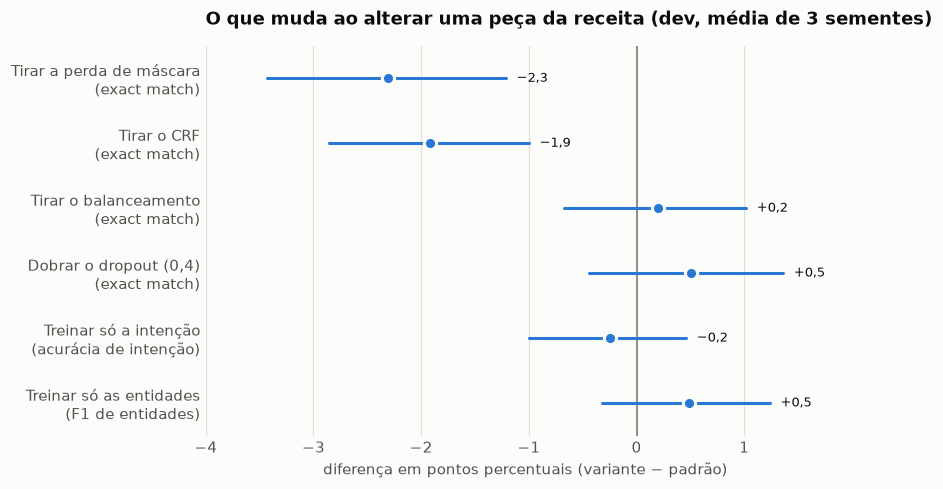

,métrica,padrão,variante,diferença,intervalo de 95%,distinguível
mudança,,,,,,
Tirar a perda de máscara,Exact match,"60,9","58,6","−2,3","−3,4 a −1,2",sim
Tirar o CRF,Exact match,"60,9","59,0","−1,9","−2,9 a −1,0",sim
Tirar o balanceamento,Exact match,"60,9","61,1","+0,2","−0,7 a +1,0",não
"Dobrar o dropout (0,4)",Exact match,"60,9","61,4","+0,5","−0,4 a +1,4",não
Treinar só a intenção,Acurácia de intenção,"82,8","82,5","−0,2","−1,0 a +0,5",não
Treinar só as entidades,F1 de entidades,"74,3","74,8","+0,5","−0,3 a +1,2",não


In [7]:
comparacoes = [
    # (variante, métrica que responde à pergunta, rótulo, pode substituir o padrão?)
    ("sem_mascara", "exact_match", "Tirar a perda de máscara", True),
    ("sem_crf", "exact_match", "Tirar o CRF", True),
    ("sem_balanceamento", "exact_match", "Tirar o balanceamento", True),
    ("mais_dropout", "exact_match", "Dobrar o dropout (0,4)", True),
    ("so_intencao", "intent_acc", "Treinar só a intenção", False),
    ("so_entidades", "slot_f1", "Treinar só as entidades", False),
]

tabelas = {v: qualidade.comparar_grupos(ouro_dev, grupo_dev["padrao"], grupo_dev[v]) for v, *_ in comparacoes}

linhas, no_grafico = [], {}
for variante, metrica, rotulo, candidata in comparacoes:
    c = tabelas[variante].loc[metrica]
    linhas.append({
        "mudança": rotulo,
        "métrica": qualidade.NOMES[metrica],
        "padrão": pts(c["a"]),
        "variante": pts(c["b"]),
        "diferença": dif(c["diferenca"]),
        "intervalo de 95%": f"{dif(c['ic_min'])} a {dif(c['ic_max'])}",
        "distinguível": "sim" if c["distinguivel"] else "não",
    })
    em_minusculas = qualidade.NOMES[metrica][0].lower() + qualidade.NOMES[metrica][1:] if metrica != "slot_f1" else qualidade.NOMES[metrica]
    no_grafico[f"{rotulo}\n({em_minusculas})"] = (100 * c["diferenca"], 100 * c["ic_min"], 100 * c["ic_max"])

fig, ax = visual.diferencas_com_intervalo(
    no_grafico, "O que muda ao alterar uma peça da receita (dev, média de 3 sementes)",
    "diferença em pontos percentuais (variante − padrão)",
)
visual.salvar(fig, PASTA, "comparacoes")
plt.show()
resumo_comparacoes = pd.DataFrame(linhas).set_index("mudança")
resumo_comparacoes

O gráfico mostra a métrica que responde à pergunta de cada linha. A tabela abaixo dá o quadro inteiro: a diferença de cada variante em todas as métricas.

In [8]:
quadro = pd.DataFrame({
    rotulo: {
        qualidade.NOMES[m]: f"{dif(tabelas[v].loc[m, 'diferenca'])}{' *' if tabelas[v].loc[m, 'distinguivel'] else ''}"
        for m in qualidade.METRICAS
    }
    for v, _, rotulo, _ in comparacoes
}).T
print("Diferença em pontos (variante − padrão), dev, média de 3 sementes.  * = intervalo de 95% não contém zero")
quadro

Diferença em pontos (variante − padrão), dev, média de 3 sementes.  * = intervalo de 95% não contém zero


,Acurácia de intenção,Macro-F1 de intenção,F1 de entidades,Exact match
Tirar a perda de máscara,"−1,8 *","−1,3","−1,2 *","−2,3 *"
Tirar o CRF,"+0,3","+0,8","−3,5 *","−1,9 *"
Tirar o balanceamento,"+0,1","+0,8","+0,1","+0,2"
"Dobrar o dropout (0,4)","+0,4","+0,5","+0,3","+0,5"
Treinar só a intenção,"−0,2","+0,3","−74,2 *","−60,8 *"
Treinar só as entidades,"−81,7 *","−79,9 *","+0,5","−60,3 *"


In [9]:
c = {v: tabelas[v] for v in tabelas}
aprovadas = [v for v, metrica, _, candidata in comparacoes if candidata and c[v].loc["exact_match", "ic_min"] > 0]


def efeito(variante, metrica):
    linha = c[variante].loc[metrica]
    return f"{dif(linha['diferenca'])} (intervalo de {dif(linha['ic_min'])} a {dif(linha['ic_max'])})"


def veredito(variante, metrica, se_piora, se_melhora):
    """Escolhe a frase conforme o intervalo da diferença (variante − padrão) fica abaixo, acima ou sobre o zero."""
    linha = c[variante].loc[metrica]
    if linha["ic_max"] < 0:
        return se_piora
    if linha["ic_min"] > 0:
        return se_melhora
    return "Sem diferença distinguível"


display(Markdown(f"""
**Leitura, uma comparação por vez.**

| Pergunta | Resultado em dev | Veredito |
|---|---|---|
| A máscara se paga? | Sem ela, exact match {efeito('sem_mascara', 'exact_match')}; F1 de entidades {efeito('sem_mascara', 'slot_f1')} | {veredito('sem_mascara', 'exact_match', 'Sim: tirar a máscara piora', 'Não: sem ela é melhor')} |
| O CRF se paga? | Sem ele, exact match {efeito('sem_crf', 'exact_match')}; F1 de entidades {efeito('sem_crf', 'slot_f1')} | {veredito('sem_crf', 'exact_match', 'Sim: tirar o CRF piora', 'Não: sem ele é melhor')} |
| O balanceamento se paga? | Sem ele, exact match {efeito('sem_balanceamento', 'exact_match')}; macro-F1 de intenção {efeito('sem_balanceamento', 'intent_macro_f1')} | {veredito('sem_balanceamento', 'exact_match', 'Sim: tirar o balanceamento piora', 'Não: sem ele é melhor')} |
| Mais dropout ajuda? | Com 0,4, exact match {efeito('mais_dropout', 'exact_match')} | {veredito('mais_dropout', 'exact_match', 'Não: piora', 'Sim: melhora')} |
| A intenção ganha por treinar junto com as entidades? | Sozinha, acurácia de intenção {efeito('so_intencao', 'intent_acc')} | {veredito('so_intencao', 'intent_acc', 'Sim: sozinha ela piora', 'Não: sozinha ela é melhor')} |
| As entidades ganham por treinar junto com a intenção? | Sozinhas, F1 de entidades {efeito('so_entidades', 'slot_f1')} | {veredito('so_entidades', 'slot_f1', 'Sim: sozinhas elas pioram', 'Não: sozinhas elas são melhores')} |

**Contra o artigo.** No NLU-Benchmark, o DIET mediu que a máscara, sem embeddings pré-treinados, rende cerca de 1 ponto nas duas tarefas, e que treinar junto sobe o F1 de entidades de 82,57 para 86,04, com a intenção caindo de 90,90 para 90,18. Nos nossos dados:

- **Máscara:** {veredito('sem_mascara', 'exact_match', 'o efeito se repete', 'o efeito não se repete: sem ela é melhor')}. Tirar a máscara muda a acurácia de intenção em {dif(c['sem_mascara'].loc['intent_acc', 'diferenca'])} e o F1 de entidades em {dif(c['sem_mascara'].loc['slot_f1', 'diferenca'])}.
- **Treino conjunto, entidades:** {veredito('so_entidades', 'slot_f1', 'o ganho do artigo se repete', 'o resultado é o contrário do artigo: sozinhas elas são melhores').replace('Sem diferença distinguível', 'o ganho do artigo **não se repete**; não há diferença distinguível entre treinar junto e separado')}.
- **Treino conjunto, intenção:** {veredito('so_intencao', 'intent_acc', 'treinar junto ajuda', 'treinar junto atrapalha, como no artigo').replace('Sem diferença distinguível', 'não há diferença distinguível')}.

O que o treino conjunto entrega de qualquer forma é **uma rede só para as duas respostas**: metade do custo de servir dois modelos, sem perda medida de qualidade.
"""))


**Leitura, uma comparação por vez.**

| Pergunta | Resultado em dev | Veredito |
|---|---|---|
| A máscara se paga? | Sem ela, exact match −2,3 (intervalo de −3,4 a −1,2); F1 de entidades −1,2 (intervalo de −2,2 a −0,2) | Sim: tirar a máscara piora |
| O CRF se paga? | Sem ele, exact match −1,9 (intervalo de −2,9 a −1,0); F1 de entidades −3,5 (intervalo de −4,5 a −2,6) | Sim: tirar o CRF piora |
| O balanceamento se paga? | Sem ele, exact match +0,2 (intervalo de −0,7 a +1,0); macro-F1 de intenção +0,8 (intervalo de −0,6 a +1,7) | Sem diferença distinguível |
| Mais dropout ajuda? | Com 0,4, exact match +0,5 (intervalo de −0,4 a +1,4) | Sem diferença distinguível |
| A intenção ganha por treinar junto com as entidades? | Sozinha, acurácia de intenção −0,2 (intervalo de −1,0 a +0,5) | Sem diferença distinguível |
| As entidades ganham por treinar junto com a intenção? | Sozinhas, F1 de entidades +0,5 (intervalo de −0,3 a +1,2) | Sem diferença distinguível |

**Contra o artigo.** No NLU-Benchmark, o DIET mediu que a máscara, sem embeddings pré-treinados, rende cerca de 1 ponto nas duas tarefas, e que treinar junto sobe o F1 de entidades de 82,57 para 86,04, com a intenção caindo de 90,90 para 90,18. Nos nossos dados:

- **Máscara:** o efeito se repete. Tirar a máscara muda a acurácia de intenção em −1,8 e o F1 de entidades em −1,2.
- **Treino conjunto, entidades:** o ganho do artigo **não se repete**; não há diferença distinguível entre treinar junto e separado.
- **Treino conjunto, intenção:** não há diferença distinguível.

O que o treino conjunto entrega de qualquer forma é **uma rede só para as duas respostas**: metade do custo de servir dois modelos, sem perda medida de qualidade.


## 5. A configuração final

Pela regra, entra na configuração final toda variante candidata cujo intervalo em exact match ficou todo acima de zero.

In [10]:
if not aprovadas:
    final, config_final, receita_final = "padrao", {}, {}
elif len(aprovadas) == 1:
    final = aprovadas[0]
    config_final, receita_final = etapa4.VARIANTES[final]["config"], etapa4.VARIANTES[final]["receita"]
else:
    # mais de uma mudança aprovada: a combinação é treinada e precisa confirmar o ganho em dev
    final = "combinada"
    config_final = {k: v for nome in aprovadas for k, v in etapa4.VARIANTES[nome]["config"].items()}
    receita_final = {k: v for nome in aprovadas for k, v in etapa4.VARIANTES[nome]["receita"].items()}
    for semente in SEMENTES:
        etapa4.executar(final, semente, {"nome": "Combinação das mudanças aprovadas", "config": config_final, "receita": receita_final})
    execucoes[final] = [etapa4.carregar(final, s) for s in SEMENTES]
    grupo_dev[final] = [e["previsoes_dev"] for e in execucoes[final]]

final_dev = grupo_dev[final]
contra_padrao = qualidade.comparar_grupos(ouro_dev, grupo_dev["padrao"], final_dev)
contra_base_dev = qualidade.comparar_grupos(ouro_dev, [base_dev], final_dev)
supera_base = bool(contra_base_dev.loc["exact_match", "ic_min"] > 0)

nomes_aprovadas = [etapa4.VARIANTES[v]["nome"] for v in aprovadas]
display(Markdown(f"""
**Mudanças aprovadas pela regra:** {", ".join(nomes_aprovadas) if nomes_aprovadas else "nenhuma"}.

**Configuração final:** {"a receita do artigo, sem alteração" if final == "padrao" else "a receita do artigo com: " + ", ".join(f"`{k} = {v}`" for k, v in {**config_final, **receita_final}.items())}.
"""))

em_dev = qualidade.intervalo_do_grupo(ouro_dev, final_dev).loc[list(qualidade.METRICAS)]
pd.DataFrame({
    "configuração final (média de 3 sementes)": em_dev["valor"].map(pts),
    "intervalo de 95%": [f"{pts(a)} a {pts(b)}" for a, b in zip(em_dev["ic_min"], em_dev["ic_max"])],
    "desvio entre sementes": em_dev["desvio_sementes"].map(pts),
    "linha de base": [pts(qualidade.avaliar(ouro_dev, base_dev)[m]) for m in qualidade.METRICAS],
    "diferença para a linha de base": [f"{dif(contra_base_dev.loc[m, 'diferenca'])} ({dif(contra_base_dev.loc[m, 'ic_min'])} a {dif(contra_base_dev.loc[m, 'ic_max'])})" for m in qualidade.METRICAS],
}).rename(index=qualidade.NOMES)


**Mudanças aprovadas pela regra:** nenhuma.

**Configuração final:** a receita do artigo, sem alteração.


,configuração final (média de 3 sementes),intervalo de 95%,desvio entre sementes,linha de base,diferença para a linha de base
Acurácia de intenção,"82,8","81,4 a 84,2","0,8","84,5","−1,7 (−2,8 a −0,6)"
Macro-F1 de intenção,"80,3","78,1 a 82,6","0,9","82,0","−1,7 (−3,7 a +0,3)"
F1 de entidades,"74,3","72,6 a 76,0","0,5","49,9","+24,4 (+22,4 a +26,5)"
Exact match,"60,9","59,0 a 62,8","0,6","45,1","+15,8 (+14,1 a +17,8)"


## 6. Resultado no teste

Com a configuração decidida em `dev`, o teste é aberto uma vez. Os três modelos finais (um por semente) respondem ao teste; o resultado é a média, com o intervalo de 95% da média e o desvio entre as sementes.

In [11]:
dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
modelos = [SistemaDiet.carregar(e["pasta"] / "modelo", dispositivo) for e in execucoes[final]]
final_teste = [m.prever(list(teste["utt"])) for m in modelos]

no_teste = qualidade.intervalo_do_grupo(ouro_teste, final_teste)
contra_base_teste = qualidade.comparar_grupos(ouro_teste, [base_teste], final_teste)
base_medida = qualidade.avaliar(ouro_teste, base_teste)

linhas = {
    "DIET do zero, rótulos humanos (média de 3 sementes)": {
        qualidade.NOMES[m]: f"{pts(no_teste.loc[m, 'valor'])} ({pts(no_teste.loc[m, 'ic_min'])} a {pts(no_teste.loc[m, 'ic_max'])})"
        for m in qualidade.METRICAS
    } | {"Parâmetros": n(modelos[0].parametros)},
    "Linha de base (Etapa 2)": {qualidade.NOMES[m]: pts(base_medida[m]) for m in qualidade.METRICAS} | {"Parâmetros": n(base_linha["parametros"])},
}
for nome, ref in massive.REFERENCIA.items():
    linhas[f"{nome} (publicado)"] = {
        "Acurácia de intenção": f"{num(ref['intent_acc'][0])} (± {num(ref['intent_acc'][1])})",
        "Macro-F1 de intenção": "n/d",
        "F1 de entidades": f"{num(ref['slot_f1'][0])} (± {num(ref['slot_f1'][1])})",
        "Exact match": f"{num(ref['exact_match'][0])} (± {num(ref['exact_match'][1])})",
        "Parâmetros": n(ref["parametros"]),
    }
pd.DataFrame(linhas).T

,Acurácia de intenção,Macro-F1 de intenção,F1 de entidades,Exact match,Parâmetros
"DIET do zero, rótulos humanos (média de 3 sementes)","82,4 (81,1 a 83,6)","80,0 (78,2 a 82,4)","72,7 (71,3 a 74,2)","60,3 (58,7 a 62,0)",4.895.834
Linha de base (Etapa 2),"84,6","81,4","47,8","45,2",3.940.300
XLM-R Base (publicado),"86,7 (± 1,2)",n/d,"73,3 (± 0,6)","64,6 (± 1,7)",270.000.000
mT5 Base (encoder) (publicado),"86,9 (± 1,2)",n/d,"74,9 (± 0,6)","66,0 (± 1,7)",258.000.000
mT5 Base (texto para texto) (publicado),"86,7 (± 1,2)",n/d,"76,6 (± 0,6)","67,6 (± 1,7)",580.000.000


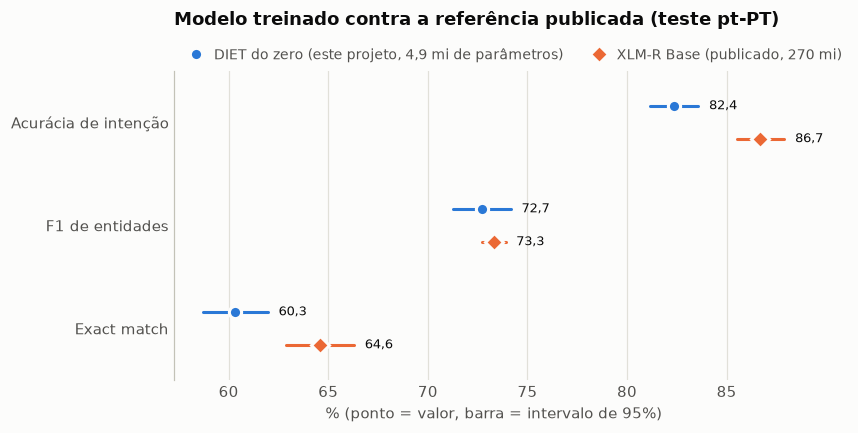


**Leitura.**

- **Contra a linha de base (pareado, teste):** exact match +15,1 pontos (intervalo de +13,4 a +16,7); F1 de entidades +24,9 (+23,0 a +26,7); acurácia de intenção −2,2 (−3,1 a −1,3).
- **Contra o XLM-R publicado:** −4,3 em acurácia de intenção, −0,6 em F1 de entidades e −4,3 em exact match, com 55 vezes menos parâmetros e sem nenhum pré-treino. A comparação é de ordem de grandeza: aquele modelo treinou com 51 idiomas.
- **Variação entre sementes no teste:** desvio de 0,4 em exact match e de 0,6 em acurácia de intenção.

**O ponto fraco: a intenção.** A rede do zero fica abaixo da linha de base em acurácia de intenção, e o intervalo não contém zero: a diferença é real. A linha de base é um classificador linear sobre dezenas de milhares de n-gramas, e é difícil de bater em intenção. O próprio artigo do DIET mede cerca de 3 pontos de intenção a menos quando não usa embeddings pré-treinados (87,10 contra 90,18). No exact match, que exige a resposta inteira, a rede ganha com folga porque as entidades pesam mais.


In [12]:
xlmr = massive.REFERENCIA["XLM-R Base"]
tres = {"intent_acc": "Acurácia de intenção", "slot_f1": "F1 de entidades", "exact_match": "Exact match"}

fig, ax = visual.pontos_com_intervalo(
    {
        "DIET do zero (este projeto, 4,9 mi de parâmetros)": {
            nome: (100 * no_teste.loc[m, "valor"], 100 * no_teste.loc[m, "ic_min"], 100 * no_teste.loc[m, "ic_max"])
            for m, nome in tres.items()
        },
        "XLM-R Base (publicado, 270 mi)": {
            nome: (xlmr[m][0], xlmr[m][0] - xlmr[m][1], xlmr[m][0] + xlmr[m][1]) for m, nome in tres.items()
        },
    },
    "Modelo treinado contra a referência publicada (teste pt-PT)",
    "% (ponto = valor, barra = intervalo de 95%)",
)
visual.salvar(fig, PASTA, "teste_contra_referencia")
plt.show()

distancia = {m: 100 * no_teste.loc[m, "valor"] - xlmr[m][0] for m in tres}
ganho = contra_base_teste
display(Markdown(f"""
**Leitura.**

- **Contra a linha de base (pareado, teste):** exact match {dif(ganho.loc['exact_match', 'diferenca'])} pontos (intervalo de {dif(ganho.loc['exact_match', 'ic_min'])} a {dif(ganho.loc['exact_match', 'ic_max'])}); F1 de entidades {dif(ganho.loc['slot_f1', 'diferenca'])} ({dif(ganho.loc['slot_f1', 'ic_min'])} a {dif(ganho.loc['slot_f1', 'ic_max'])}); acurácia de intenção {dif(ganho.loc['intent_acc', 'diferenca'])} ({dif(ganho.loc['intent_acc', 'ic_min'])} a {dif(ganho.loc['intent_acc', 'ic_max'])}).
- **Contra o XLM-R publicado:** {sinal(distancia['intent_acc'])} em acurácia de intenção, {sinal(distancia['slot_f1'])} em F1 de entidades e {sinal(distancia['exact_match'])} em exact match, com {num(xlmr['parametros'] / modelos[0].parametros, 0)} vezes menos parâmetros e sem nenhum pré-treino. A comparação é de ordem de grandeza: aquele modelo treinou com 51 idiomas.
- **Variação entre sementes no teste:** desvio de {pts(no_teste.loc['exact_match', 'desvio_sementes'])} em exact match e de {pts(no_teste.loc['intent_acc', 'desvio_sementes'])} em acurácia de intenção.

**O ponto fraco: a intenção.** A rede do zero fica {"abaixo" if ganho.loc['intent_acc', 'diferenca'] < 0 else "acima"} da linha de base em acurácia de intenção, e o intervalo {"não contém zero: a diferença é real" if ganho.loc['intent_acc', 'distinguivel'] else "contém zero"}. A linha de base é um classificador linear sobre dezenas de milhares de n-gramas, e é difícil de bater em intenção. O próprio artigo do DIET mede cerca de 3 pontos de intenção a menos quando não usa embeddings pré-treinados (87,10 contra 90,18). No exact match, que exige a resposta inteira, a rede ganha com folga porque as entidades pesam mais.
"""))

## 7. Onde o modelo ainda erra

Diagnóstico feito em `dev`, para que as próximas etapas possam agir sobre ele sem tocar no teste.

### 7.1 Que parte da resposta falha

In [13]:
def tipos_de_erro(rotulos_humanos, previsoes):
    intencao_certa = np.array([o.intent == p.intent for o, p in zip(rotulos_humanos, previsoes)])
    entidades_certas = np.array([set(o.slots) == set(p.slots) for o, p in zip(rotulos_humanos, previsoes)])
    return {
        "Tudo certo": (intencao_certa & entidades_certas).mean(),
        "Só as entidades erradas": (intencao_certa & ~entidades_certas).mean(),
        "Só a intenção errada": (~intencao_certa & entidades_certas).mean(),
        "As duas erradas": (~intencao_certa & ~entidades_certas).mean(),
    }


erros = pd.DataFrame({
    "DIET do zero (média de 3 sementes)": pd.DataFrame([tipos_de_erro(ouro_dev, p) for p in final_dev]).mean(),
    "Linha de base": pd.Series(tipos_de_erro(ouro_dev, base_dev)),
})
erros.map(lambda v: pts(v) + "%")

,DIET do zero (média de 3 sementes),Linha de base
Tudo certo,"60,9%","45,1%"
Só as entidades erradas,"21,9%","39,4%"
Só a intenção errada,"10,0%","7,2%"
As duas erradas,"7,2%","8,3%"


### 7.2 Enunciados já vistos e enunciados inéditos

A Etapa 1 marcou os enunciados de `dev` cujo texto exato também está no treino. Separar os dois grupos mostra quanto do resultado é memória.

In [14]:
visto = dev["utt_in_train"].to_numpy()


def recorte(mascara, previsoes):
    indices = np.flatnonzero(mascara)
    return qualidade.avaliar([ouro_dev[i] for i in indices], [previsoes[i] for i in indices])


memoria = pd.DataFrame({
    f"texto também no treino ({n(visto.sum())})": pd.DataFrame([recorte(visto, p) for p in final_dev]).mean(),
    f"texto inédito ({n((~visto).sum())})": pd.DataFrame([recorte(~visto, p) for p in final_dev]).mean(),
}).loc[list(qualidade.METRICAS)].rename(index=qualidade.NOMES)
memoria.map(pts)

,texto também no treino (143),texto inédito (1.890)
Acurácia de intenção,"97,0","81,7"
Macro-F1 de intenção,"94,3","79,0"
F1 de entidades,"96,4","73,4"
Exact match,"93,7","58,4"


### 7.3 Entidades: o tamanho da classe

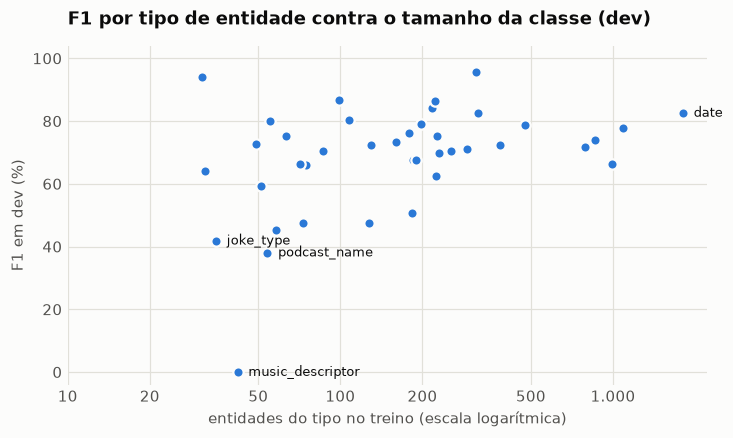


**Leitura.**

- O modelo acerta a resposta inteira em 60,9% de `dev`, contra 45,1% da linha de base. O ganho veio das entidades: os casos de "só as entidades erradas" caíram de 39,4% para 21,9%.
- O erro que resta ainda é mais de entidades (21,9%) do que de intenção (10,0%).
- Nos enunciados cujo texto está no treino, o exact match é de 93,7; nos inéditos, 58,4. O número que descreve a generalização é o dos inéditos.
- Os 16 tipos de entidade com menos de 100 exemplos de treino têm F1 médio de 61,1; os 25 com 100 ou mais, 73,4. O gráfico só mostra tipos com pelo menos 5 exemplos em `dev`.


In [15]:
por_tipo = sum(qualidade.por_tipo_de_entidade(ouro_dev, p)[["f1"]].reindex(rotulos["slot_types"]).fillna(0) for p in final_dev) / len(final_dev)
no_dev = qualidade.por_tipo_de_entidade(ouro_dev, ouro_dev)["exemplos"].reindex(rotulos["slot_types"]).fillna(0)
exemplos_treino = qualidade.por_tipo_de_entidade(ouro(treino), ouro(treino))["exemplos"].reindex(rotulos["slot_types"]).fillna(0)
tipos = pd.DataFrame({"f1": por_tipo["f1"], "treino": exemplos_treino, "dev": no_dev})
tipos = tipos[(tipos["dev"] >= 5) & (tipos["treino"] > 0)]   # com menos de 5 exemplos em dev o F1 não diz nada

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.scatter(tipos["treino"], 100 * tipos["f1"], s=46, color=visual.AZUL, edgecolor=visual.SUPERFICIE, linewidth=1.5)
ax.set_xscale("log")
ax.set_xticks([10, 20, 50, 100, 200, 500, 1000], ["10", "20", "50", "100", "200", "500", "1.000"])
ax.minorticks_off()
ax.set_ylim(-4, 104)
ax.grid(True)
ax.spines["bottom"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.set_title("F1 por tipo de entidade contra o tamanho da classe (dev)")
ax.set_xlabel("entidades do tipo no treino (escala logarítmica)")
ax.set_ylabel("F1 em dev (%)")
for tipo, linha in pd.concat([tipos.nsmallest(3, "f1"), tipos.nlargest(1, "treino")]).iterrows():
    ax.annotate(tipo, (linha["treino"], 100 * linha["f1"]), xytext=(7, 0), textcoords="offset points",
                va="center", fontsize=8.5, color=visual.TINTA)
visual.salvar(fig, PASTA, "f1_por_tipo_de_entidade")
plt.show()

poucos, muitos = tipos[tipos["treino"] < 100], tipos[tipos["treino"] >= 100]
so_entidades = erros.loc["Só as entidades erradas", "DIET do zero (média de 3 sementes)"]
so_intencao = erros.loc["Só a intenção errada", "DIET do zero (média de 3 sementes)"]
display(Markdown(f"""
**Leitura.**

- O modelo acerta a resposta inteira em {pts(erros.loc['Tudo certo', 'DIET do zero (média de 3 sementes)'])}% de `dev`, contra {pts(erros.loc['Tudo certo', 'Linha de base'])}% da linha de base. O ganho veio das entidades: os casos de "só as entidades erradas" caíram de {pts(erros.loc['Só as entidades erradas', 'Linha de base'])}% para {pts(so_entidades)}%.
- O erro que resta ainda é mais de entidades ({pts(so_entidades)}%) do que de intenção ({pts(so_intencao)}%).
- Nos enunciados cujo texto está no treino, o exact match é de {pts(memoria.iloc[3, 0])}; nos inéditos, {pts(memoria.iloc[3, 1])}. O número que descreve a generalização é o dos inéditos.
- Os {len(poucos)} tipos de entidade com menos de 100 exemplos de treino têm F1 médio de {pts(poucos['f1'].mean())}; os {len(muitos)} com 100 ou mais, {pts(muitos['f1'].mean())}. O gráfico só mostra tipos com pelo menos 5 exemplos em `dev`.
"""))

## 8. Eficiência

Mesmo protocolo das Etapas 2 e 3: uma consulta por vez, 1.024 consultas, 1 núcleo de CPU. O modelo medido é o da semente 0.

In [16]:
na_cpu = SistemaDiet.carregar(execucoes[final][0]["pasta"] / "modelo", "cpu")
tempos = eficiencia.medir_latencia(na_cpu, list(dev["utt"]))
latencia = eficiencia.resumir_latencia(tempos)
bytes_modelo = sum(p.stat().st_size for p in (execucoes[final][0]["pasta"] / "modelo").iterdir())
pd.DataFrame({
    "DIET do zero (treinado)": {
        "Exact match no teste": pts(no_teste.loc["exact_match", "valor"]),
        "Latência p50 (ms)": num(latencia["latencia_p50_ms"], 2),
        "Latência p95 (ms)": num(latencia["latencia_p95_ms"], 2),
        "Latência p99 (ms)": num(latencia["latencia_p99_ms"], 2),
        "Parâmetros": n(na_cpu.parametros),
        "Tamanho em disco (MB)": num(bytes_modelo / 1e6),
    },
    "Linha de base": {
        "Exact match no teste": pts(base_linha["exact_match"]),
        "Latência p50 (ms)": num(base_linha["latencia_p50_ms"], 2),
        "Latência p95 (ms)": num(base_linha["latencia_p95_ms"], 2),
        "Latência p99 (ms)": num(base_linha["latencia_p99_ms"], 2),
        "Parâmetros": n(base_linha["parametros"]),
        "Tamanho em disco (MB)": num(base_linha["bytes"] / 1e6),
    },
})

,DIET do zero (treinado),Linha de base
Exact match no teste,"60,3","45,2"
Latência p50 (ms),"1,25","0,82"
Latência p95 (ms),"1,74","1,08"
Latência p99 (ms),"2,10","1,33"
Parâmetros,4.895.834,3.940.300
Tamanho em disco (MB),"19,9","33,0"


## 9. Entrega

Os três modelos finais vão para a entrega: as etapas de destilação, poda e quantização partem deles. As execuções das variantes ficam no cache; a entrega guarda só os seus resultados.

In [17]:
nome_do_sistema = "DIET do zero (rótulos humanos)"
linhas_resultado = []
(PASTA / "historicos").mkdir(exist_ok=True)
for i, semente in enumerate(SEMENTES):
    destino = PASTA / "modelos" / f"semente_{semente}"
    if destino.exists():
        shutil.rmtree(destino)
    shutil.copytree(execucoes[final][i]["pasta"] / "modelo", destino)
    execucoes[final][i]["historico"].to_csv(PASTA / "historicos" / f"semente_{semente}.csv", index=False)
    salvar_previsoes(PASTA / "previsoes" / f"semente_{semente}_dev.parquet", dev["id"], final_dev[i])
    salvar_previsoes(PASTA / "previsoes" / f"semente_{semente}_test.parquet", teste["id"], final_teste[i])
    for particao, rotulos_humanos, previsoes in (("dev", ouro_dev, final_dev[i]), ("test", ouro_teste, final_teste[i])):
        linhas_resultado.append(resultados.registrar(
            f"{nome_do_sistema}, semente {semente}", particao, rotulos_humanos, previsoes,
            parametros=na_cpu.parametros, bytes_em_disco=bytes_modelo, semente=semente,
        ))
for particao, rotulos_humanos, grupo in (("dev", ouro_dev, final_dev), ("test", ouro_teste, final_teste)):
    linhas_resultado.append(resultados.registrar_grupo(
        f"{nome_do_sistema}, média de {len(SEMENTES)} sementes", particao, rotulos_humanos, grupo,
        tempos_ms=tempos, parametros=na_cpu.parametros, bytes_em_disco=bytes_modelo, threads=1,
    ))
resultados.salvar(linhas_resultado, PASTA)

# as comparações, variante por variante e métrica por métrica
pd.concat(
    {etapa4.VARIANTES[v]["nome"]: t.loc[list(qualidade.METRICAS)] for v, t in tabelas.items()}, names=["variante", "metrica"]
).to_csv(PASTA / "comparacoes.csv")

manifesto = {
    "etapa": "04_treino",
    "gerado_em": date.today().isoformat(),
    "entrada": ["entregas/01_dados", "entregas/02_avaliacao", "entregas/03_arquitetura"],
    "configuracao_final": {"variante": final, "config": execucoes[final][0]["meta"]["config"], "receita": execucoes[final][0]["meta"]["receita"]},
    "sementes": list(SEMENTES),
    "melhor_epoca": {str(s): e["meta"]["melhor_epoca"] for s, e in zip(SEMENTES, execucoes[final])},
    "regra_de_decisao": "IC95 da diferença de exact match em dev (média de 3 sementes) todo acima de zero",
    "variantes_aprovadas": aprovadas,
    "ambiente": {**eficiencia.ambiente(), "torch": torch.__version__,
                 "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None},
}
(PASTA / "manifesto.json").write_text(json.dumps(manifesto, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")

# Um modelo relido da entrega reproduz as previsões gravadas?
relido = SistemaDiet.carregar(PASTA / "modelos" / "semente_0", "cpu")
_, gravadas = carregar_previsoes(PASTA / "previsoes" / "semente_0_test.parquet")
recarrega_ok = relido.prever(list(teste["utt"])) == gravadas
print("Modelo relido da entrega reproduz as previsões do teste:", "sim" if recarrega_ok else "NÃO")

Modelo relido da entrega reproduz as previsões do teste: sim


### Critério de pronto

In [18]:
pronto = pd.Series({
    "Configuração final com 3 sementes treinadas": len(final_teste) == 3,
    "Comparações decididas em dev pela regra escrita antes": True,
    "Supera a linha de base em exact match de forma distinguível (dev)": supera_base,
    "Teste aberto uma vez, com intervalo de confiança": bool(no_teste["ic_min"].notna().all()),
    "Modelo relido do disco reproduz o resultado": bool(recarrega_ok),
}).map({True: "sim", False: "NÃO"}).rename("atendido").to_frame()
assert (pronto["atendido"] == "sim").all()
pronto

,atendido
Configuração final com 3 sementes treinadas,sim
Comparações decididas em dev pela regra escrita antes,sim
Supera a linha de base em exact match de forma distinguível (dev),sim
"Teste aberto uma vez, com intervalo de confiança",sim
Modelo relido do disco reproduz o resultado,sim


## 10. Resposta

O resumo abaixo é gerado a partir dos números calculados neste notebook e gravado em `entregas/04_treino/RESUMO.md`.

In [19]:
# O resumo afirma os resultados abaixo em texto corrido. Se um treino novo mudar algum deles,
# a execução para aqui e o texto precisa ser revisto.
e = lambda variante, metrica: tabelas[variante].loc[metrica]
assert e("sem_mascara", "exact_match")["ic_max"] < 0 and e("sem_crf", "exact_match")["ic_max"] < 0
assert not e("sem_balanceamento", "exact_match")["distinguivel"] and not e("mais_dropout", "exact_match")["distinguivel"]
assert not e("so_entidades", "slot_f1")["distinguivel"] and not e("so_intencao", "intent_acc")["distinguivel"]
assert contra_base_teste.loc["intent_acc", "ic_max"] < 0 and final == "padrao"


def linha_teste(nome, valores, parametros):
    return f"| {nome} | {valores['intent_acc']} | {valores['intent_macro_f1']} | {valores['slot_f1']} | {valores['exact_match']} | {parametros} |"


nosso = {m: f"{pts(no_teste.loc[m, 'valor'])} ({pts(no_teste.loc[m, 'ic_min'])} a {pts(no_teste.loc[m, 'ic_max'])})" for m in qualidade.METRICAS}
da_base = {m: pts(base_medida[m]) for m in qualidade.METRICAS}
do_xlmr = {"intent_acc": num(xlmr["intent_acc"][0]), "intent_macro_f1": "n/d", "slot_f1": num(xlmr["slot_f1"][0]), "exact_match": num(xlmr["exact_match"][0])}

tabela_comparacoes = "\n".join(
    f"| {rotulo} | {qualidade.NOMES[metrica]} | {dif(tabelas[v].loc[metrica, 'diferenca'])} | {dif(tabelas[v].loc[metrica, 'ic_min'])} a {dif(tabelas[v].loc[metrica, 'ic_max'])} | {'sim' if tabelas[v].loc[metrica, 'distinguivel'] else 'não'} |"
    for v, metrica, rotulo, _ in comparacoes
)

resumo = f"""# Etapa 4 · Treino com rótulos humanos: resumo da entrega

**Pergunta.** Até onde a arquitetura chega quando aprende com rótulos humanos?

**Resposta.** No teste, a rede do zero faz **{pts(no_teste.loc['exact_match', 'valor'])} de exact match**, {pts(no_teste.loc['slot_f1', 'valor'])} de F1 de entidades e {pts(no_teste.loc['intent_acc', 'valor'])} de acurácia de intenção (média de 3 sementes). São {dif(contra_base_teste.loc['exact_match', 'diferenca'])} pontos de exact match em relação à linha de base e {sinal(distancia['exact_match'])} em relação ao XLM-R publicado, que tem {num(xlmr['parametros'] / modelos[0].parametros, 0)} vezes mais parâmetros e pré-treino. Este é o **teto** do projeto: o que a arquitetura faz com os rótulos certos.

## Resultado no teste (pt-PT, {n(len(teste))} enunciados)

| Sistema | Intenção (acurácia) | Intenção (macro-F1) | Entidades (F1) | Exact match | Parâmetros |
|---|---|---|---|---|---|
{linha_teste("DIET do zero, rótulos humanos (média de 3 sementes, intervalo de 95%)", nosso, n(modelos[0].parametros))}
{linha_teste("Linha de base (Etapa 2)", da_base, n(base_linha["parametros"]))}
{linha_teste("XLM-R Base (publicado)", do_xlmr, n(xlmr["parametros"]))}

O modelo publicado treinou com os 51 idiomas juntos; o deste projeto, só com pt-PT.

![Contra a referência](figuras/teste_contra_referencia.png)

Diferença para a linha de base, pareada, no teste: intenção {dif(contra_base_teste.loc['intent_acc', 'diferenca'])} ({dif(contra_base_teste.loc['intent_acc', 'ic_min'])} a {dif(contra_base_teste.loc['intent_acc', 'ic_max'])}); entidades {dif(contra_base_teste.loc['slot_f1', 'diferenca'])} ({dif(contra_base_teste.loc['slot_f1', 'ic_min'])} a {dif(contra_base_teste.loc['slot_f1', 'ic_max'])}); exact match {dif(contra_base_teste.loc['exact_match', 'diferenca'])} ({dif(contra_base_teste.loc['exact_match', 'ic_min'])} a {dif(contra_base_teste.loc['exact_match', 'ic_max'])}).

## O ponto fraco: a intenção

Em acurácia de intenção, a rede do zero fica {dif(contra_base_teste.loc['intent_acc', 'diferenca'])} pontos em relação à linha de base no teste (intervalo de {dif(contra_base_teste.loc['intent_acc', 'ic_min'])} a {dif(contra_base_teste.loc['intent_acc', 'ic_max'])}). Um saco de n-gramas com classificador linear é difícil de bater em intenção, e o próprio artigo do DIET mede cerca de 3 pontos a menos de intenção sem embeddings pré-treinados. O ganho da rede está todo nas entidades, e é ele que carrega o exact match.

## O que cada peça da receita acrescenta (dev, média de 3 sementes)

Diferença da variante em relação ao padrão. Negativo quer dizer que tirar a peça piora.

| Mudança | Métrica | Diferença | Intervalo de 95% | Distinguível |
|---|---|---|---|---|
{tabela_comparacoes}

![Comparações](figuras/comparacoes.png)

**Configuração final:** {"a receita do artigo, sem alteração" if final == "padrao" else "a receita do artigo com " + ", ".join(f"{k} = {v}" for k, v in {**config_final, **receita_final}.items())}. Regra: uma variante só substitui o padrão se o intervalo de 95% da diferença em exact match, em dev, ficar todo acima de zero.

O que se repetiu do artigo e o que não:

- **Máscara e CRF se pagam.** Tirar qualquer um dos dois piora o exact match de forma distinguível.
- **O ganho do treino conjunto não se repetiu.** Treinar as entidades sozinhas dá {dif(tabelas['so_entidades'].loc['slot_f1', 'diferenca'])} de F1 ({dif(tabelas['so_entidades'].loc['slot_f1', 'ic_min'])} a {dif(tabelas['so_entidades'].loc['slot_f1', 'ic_max'])}); treinar a intenção sozinha dá {dif(tabelas['so_intencao'].loc['intent_acc', 'diferenca'])} de acurácia ({dif(tabelas['so_intencao'].loc['intent_acc', 'ic_min'])} a {dif(tabelas['so_intencao'].loc['intent_acc', 'ic_max'])}). O treino conjunto continua valendo pelo custo: uma rede para as duas respostas.
- **Balanceamento e dropout maior não fizeram diferença distinguível.**

## Onde o modelo ainda erra (dev)

- Resposta inteira certa em {pts(erros.loc['Tudo certo', 'DIET do zero (média de 3 sementes)'])}% dos enunciados; só as entidades erradas em {pts(so_entidades)}%; só a intenção errada em {pts(so_intencao)}%.
- Exact match de {pts(memoria.iloc[3, 0])} nos enunciados cujo texto está no treino e de {pts(memoria.iloc[3, 1])} nos inéditos.
- Tipos de entidade com menos de 100 exemplos de treino: F1 médio de {pts(poucos['f1'].mean())}, contra {pts(muitos['f1'].mean())} dos demais.

## Eficiência (1 núcleo de CPU, uma consulta por vez)

| | DIET do zero | Linha de base |
|---|---|---|
| Latência p50 | {num(latencia['latencia_p50_ms'], 2)} ms | {num(base_linha['latencia_p50_ms'], 2)} ms |
| Latência p95 | {num(latencia['latencia_p95_ms'], 2)} ms | {num(base_linha['latencia_p95_ms'], 2)} ms |
| Parâmetros | {n(na_cpu.parametros)} | {n(base_linha['parametros'])} |
| Tamanho em disco | {num(bytes_modelo / 1e6)} MB | {num(base_linha['bytes'] / 1e6)} MB |

## Limites

- A época de parada e as comparações usam o mesmo `dev`. O teste só confirma a configuração final.
- Três sementes dão uma ideia da variação do treino, não uma estimativa precisa dela.
- A GPU não é determinística em todas as operações: reexecutar um treino pode mudar o resultado na casa dos décimos. Os resultados desta entrega são os das execuções gravadas.
- A referência publicada usa treino multilíngue; a comparação com ela é de ordem de grandeza.

## Arquivos

| Arquivo | Conteúdo |
|---|---|
| `modelos/semente_0`, `semente_1`, `semente_2` | Os três modelos finais: pesos, vocabulário de features e configuração |
| `resultados.csv` | Uma linha por semente e partição, mais a média das sementes |
| `previsoes/` | As respostas de cada semente em dev e teste |
| `comparacoes.csv` | Cada variante contra o padrão, em todas as métricas |
| `historicos/` | Perdas e métricas em dev, época por época, de cada semente |
| `manifesto.json` | Configuração final, receita, épocas escolhidas, ambiente |
| `figuras/` | Os gráficos deste notebook |
| `04_treino.html` | Este notebook executado, para leitura |

Para carregar o modelo nas próximas etapas:

```python
from especialista.caminhos import ENTREGAS
from especialista.modelos.diet import SistemaDiet

sistema = SistemaDiet.carregar(ENTREGAS / "04_treino" / "modelos" / "semente_0")
sistema.prever(["acorda-me às nove da manhã"])
```
"""
(PASTA / "RESUMO.md").write_text(resumo, encoding="utf-8")
display(Markdown(resumo))

# Etapa 4 · Treino com rótulos humanos: resumo da entrega

**Pergunta.** Até onde a arquitetura chega quando aprende com rótulos humanos?

**Resposta.** No teste, a rede do zero faz **60,3 de exact match**, 72,7 de F1 de entidades e 82,4 de acurácia de intenção (média de 3 sementes). São +15,1 pontos de exact match em relação à linha de base e −4,3 em relação ao XLM-R publicado, que tem 55 vezes mais parâmetros e pré-treino. Este é o **teto** do projeto: o que a arquitetura faz com os rótulos certos.

## Resultado no teste (pt-PT, 2.974 enunciados)

| Sistema | Intenção (acurácia) | Intenção (macro-F1) | Entidades (F1) | Exact match | Parâmetros |
|---|---|---|---|---|---|
| DIET do zero, rótulos humanos (média de 3 sementes, intervalo de 95%) | 82,4 (81,1 a 83,6) | 80,0 (78,2 a 82,4) | 72,7 (71,3 a 74,2) | 60,3 (58,7 a 62,0) | 4.895.834 |
| Linha de base (Etapa 2) | 84,6 | 81,4 | 47,8 | 45,2 | 3.940.300 |
| XLM-R Base (publicado) | 86,7 | n/d | 73,3 | 64,6 | 270.000.000 |

O modelo publicado treinou com os 51 idiomas juntos; o deste projeto, só com pt-PT.

![Contra a referência](figuras/teste_contra_referencia.png)

Diferença para a linha de base, pareada, no teste: intenção −2,2 (−3,1 a −1,3); entidades +24,9 (+23,0 a +26,7); exact match +15,1 (+13,4 a +16,7).

## O ponto fraco: a intenção

Em acurácia de intenção, a rede do zero fica −2,2 pontos em relação à linha de base no teste (intervalo de −3,1 a −1,3). Um saco de n-gramas com classificador linear é difícil de bater em intenção, e o próprio artigo do DIET mede cerca de 3 pontos a menos de intenção sem embeddings pré-treinados. O ganho da rede está todo nas entidades, e é ele que carrega o exact match.

## O que cada peça da receita acrescenta (dev, média de 3 sementes)

Diferença da variante em relação ao padrão. Negativo quer dizer que tirar a peça piora.

| Mudança | Métrica | Diferença | Intervalo de 95% | Distinguível |
|---|---|---|---|---|
| Tirar a perda de máscara | Exact match | −2,3 | −3,4 a −1,2 | sim |
| Tirar o CRF | Exact match | −1,9 | −2,9 a −1,0 | sim |
| Tirar o balanceamento | Exact match | +0,2 | −0,7 a +1,0 | não |
| Dobrar o dropout (0,4) | Exact match | +0,5 | −0,4 a +1,4 | não |
| Treinar só a intenção | Acurácia de intenção | −0,2 | −1,0 a +0,5 | não |
| Treinar só as entidades | F1 de entidades | +0,5 | −0,3 a +1,2 | não |

![Comparações](figuras/comparacoes.png)

**Configuração final:** a receita do artigo, sem alteração. Regra: uma variante só substitui o padrão se o intervalo de 95% da diferença em exact match, em dev, ficar todo acima de zero.

O que se repetiu do artigo e o que não:

- **Máscara e CRF se pagam.** Tirar qualquer um dos dois piora o exact match de forma distinguível.
- **O ganho do treino conjunto não se repetiu.** Treinar as entidades sozinhas dá +0,5 de F1 (−0,3 a +1,2); treinar a intenção sozinha dá −0,2 de acurácia (−1,0 a +0,5). O treino conjunto continua valendo pelo custo: uma rede para as duas respostas.
- **Balanceamento e dropout maior não fizeram diferença distinguível.**

## Onde o modelo ainda erra (dev)

- Resposta inteira certa em 60,9% dos enunciados; só as entidades erradas em 21,9%; só a intenção errada em 10,0%.
- Exact match de 93,7 nos enunciados cujo texto está no treino e de 58,4 nos inéditos.
- Tipos de entidade com menos de 100 exemplos de treino: F1 médio de 61,1, contra 73,4 dos demais.

## Eficiência (1 núcleo de CPU, uma consulta por vez)

| | DIET do zero | Linha de base |
|---|---|---|
| Latência p50 | 1,25 ms | 0,82 ms |
| Latência p95 | 1,74 ms | 1,08 ms |
| Parâmetros | 4.895.834 | 3.940.300 |
| Tamanho em disco | 19,9 MB | 33,0 MB |

## Limites

- A época de parada e as comparações usam o mesmo `dev`. O teste só confirma a configuração final.
- Três sementes dão uma ideia da variação do treino, não uma estimativa precisa dela.
- A GPU não é determinística em todas as operações: reexecutar um treino pode mudar o resultado na casa dos décimos. Os resultados desta entrega são os das execuções gravadas.
- A referência publicada usa treino multilíngue; a comparação com ela é de ordem de grandeza.

## Arquivos

| Arquivo | Conteúdo |
|---|---|
| `modelos/semente_0`, `semente_1`, `semente_2` | Os três modelos finais: pesos, vocabulário de features e configuração |
| `resultados.csv` | Uma linha por semente e partição, mais a média das sementes |
| `previsoes/` | As respostas de cada semente em dev e teste |
| `comparacoes.csv` | Cada variante contra o padrão, em todas as métricas |
| `historicos/` | Perdas e métricas em dev, época por época, de cada semente |
| `manifesto.json` | Configuração final, receita, épocas escolhidas, ambiente |
| `figuras/` | Os gráficos deste notebook |
| `04_treino.html` | Este notebook executado, para leitura |

Para carregar o modelo nas próximas etapas:

```python
from especialista.caminhos import ENTREGAS
from especialista.modelos.diet import SistemaDiet

sistema = SistemaDiet.carregar(ENTREGAS / "04_treino" / "modelos" / "semente_0")
sistema.prever(["acorda-me às nove da manhã"])
```


In [20]:
arquivos = sorted(p for p in PASTA.rglob("*") if p.is_file())
pd.DataFrame(
    {"tamanho (KB)": [round(p.stat().st_size / 1024, 1) for p in arquivos]},
    index=[str(p.relative_to(RAIZ)) for p in arquivos],
)

,tamanho (KB)
entregas/04_treino/04_treino.html,784.2
entregas/04_treino/RESUMO.md,5.1
entregas/04_treino/comparacoes.csv,3.7
entregas/04_treino/figuras/comparacoes.png,77.4
entregas/04_treino/figuras/f1_por_tipo_de_entidade.png,49.2
entregas/04_treino/figuras/teste_contra_referencia.png,58.0
entregas/04_treino/figuras/treino_padrao.png,139.7
entregas/04_treino/historicos/semente_0.csv,10.7
entregas/04_treino/historicos/semente_1.csv,10.7
entregas/04_treino/historicos/semente_2.csv,10.7
